# RSEc MCP server: demo

An LLM agent that needs bioinformatics tools can ask this server, which answers with SPARQL queries over
the [Research Software Ecosystem](https://github.com/research-software-ecosystem/content) RDF data
(bio.tools records typed with [EDAM](https://edamontology.org) terms). Here we play the agent on two questions:

1. *"I need to trim reads, align my reads, perform quality control and quantify RNA-seq data. Can you list bioinformatics tools doing that?"*
2. *"Can I compose together HISAT2 and Kallisto? Justify the composition based on EDAM terms."*

Every cell below calls the **MCP tools** of `server.py`, in-process, as an MCP client would.
The first call loads about one million triples (about 10 s once the files are downloaded); later calls are SPARQL queries on the loaded graph.

In [1]:
import os, sys, time

os.environ.setdefault("RSEC_LOG_LEVEL", "WARNING")  # keep the loading logs out of the notebook
sys.path.insert(0, "..")                            # the project modules live in mcp/

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from fastmcp import Client

import edam
import server

sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


CALLS = []  # (tool, arguments, seconds), shown at the end


async def tool(name, **arguments):
    """Call one MCP tool and return its result, as an agent would."""
    t0 = time.perf_counter()
    async with Client(server.mcp) as client:
        result = (await client.call_tool(name, arguments)).data
    CALLS.append((name, str(arguments)[:70], time.perf_counter() - t0))
    return result


t0 = time.perf_counter()
async with Client(server.mcp) as client:
    catalogue = await client.list_tools()
    first = await client.call_tool("list_software_with_biotools_ids", {"limit": 1})  # waits for the data
print(f"server ready in {time.perf_counter() - t0:.1f} s")
pd.DataFrame(
    [(t.name, (t.description or "").strip().splitlines()[0]) for t in catalogue],
    columns=["tool", "what it does"],
)

server ready in 7.0 s


,tool,what it does
0,list_software_with_biotools_ids,List software applications of the RSEc RDF data that have a bio.tools identi...
1,resolve_edam_term,"Find EDAM terms (topics, operations, data types, formats) from free text."
2,search_software,"Search bio.tools software of the RSEc data by EDAM topic, EDAM operation and..."
3,list_licenses,"List the licenses used by tools, with the number of tools, most used first."
4,get_software_io,Show the annotated inputs and outputs of a tool.
5,check_composability,Check whether the outputs of `producer` can feed the inputs of `consumer`.


## 1. Which tools trim, align, check and quantify RNA-seq reads?

The agent starts by turning each step into an **EDAM operation**. `resolve_edam_term` searches labels,
synonyms and definitions, and returns the id to use in the next calls.

In [2]:
STEPS = {
    "1. trim reads": "trimming",
    "2. align reads": "read mapping",
    "3. quality control": "sequencing quality control",
    "4. quantify RNA-seq": "RNA-Seq quantification",
}

resolved = {}
rows = []
for step, phrase in STEPS.items():
    res = await tool("resolve_edam_term", text=phrase, kind="operation", limit=3)
    best = res["results"][0]
    resolved[step] = best
    rows.append({
        "step": step,
        "asked for": phrase,
        "EDAM operation": f"{best['id']}  {best['label']}",
        "matched on": best["matched"],
        "other candidates": ", ".join(f"{r['id']} {r['label']}" for r in res["results"][1:]),
    })
pd.DataFrame(rows)

,step,asked for,EDAM operation,matched on,other candidates
0,1. trim reads,trimming,operation_3192 Sequence trimming,synonym,
1,2. align reads,read mapping,operation_3198 Read mapping,label,"operation_3199 Split read mapping, operation_3186 Bisulfite mapping"
2,3. quality control,sequencing quality control,operation_3218 Sequencing quality control,label,
3,4. quantify RNA-seq,RNA-Seq quantification,operation_3800 RNA-Seq quantification,label,


Now one search per step (this is the slowest part of the demo: each search is a SPARQL query that walks the EDAM hierarchy and the annotations of tens of thousands of tools). `search_software` always includes the **narrower** EDAM terms
(for example *Split read mapping* under *Read mapping*). The EDAM topic **RNA-Seq** (`topic_3170`)
narrows each list to tools that bio.tools describes as RNA-seq tools.

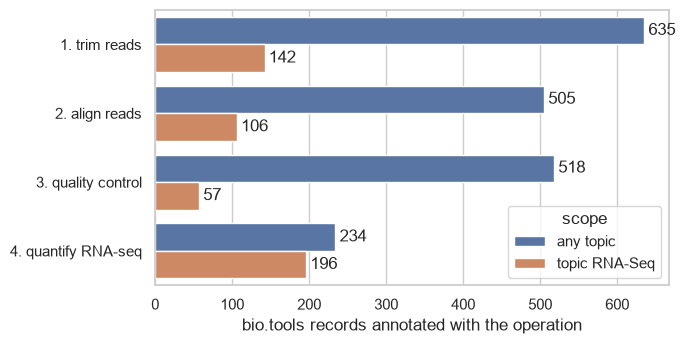

In [3]:
RNASEQ = "topic_3170"

found = {}
counts = []
for step, term in resolved.items():
    everything = await tool("search_software", operations=[term["id"]], limit=1)
    rnaseq = await tool("search_software", operations=[term["id"]], topics=[RNASEQ], limit=100)
    found[step] = rnaseq
    counts += [
        {"step": step, "scope": "any topic", "tools": everything["total"]},
        {"step": step, "scope": "topic RNA-Seq", "tools": rnaseq["total"]},
    ]
counts = pd.DataFrame(counts)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.barplot(data=counts, y="step", x="tools", hue="scope", ax=ax)
ax.set(xlabel="bio.tools records annotated with the operation", ylabel="")
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

### The tools, step by step

The first tools of each list, sorted by name, with their licenses and what bio.tools says they do.
These lists reflect how the bio.tools curators and tool authors **annotated** their records: a broad operation such as
*Sequence trimming* is attached to many tools, so the lists are candidates to review, not a ranking.

In [4]:
from IPython.display import display, Markdown

for step, res in found.items():
    op = resolved[step]
    display(Markdown(f"**{step}**: {op['id']} *{op['label']}*, {res['total']} tools tagged RNA-Seq"))
    display(pd.DataFrame(
        [{
            "tool": r["biotools_id"],
            "license": ", ".join(r["licenses"][:2]),
            "description": r["description"][:100],
        } for r in res["results"][:8]]
    ))

**1. trim reads**: operation_3192 *Sequence trimming*, 142 tools tagged RNA-Seq

,tool,license,description
0,a2tea,MIT,A2TEA is a software workflow facilitating identification of candidate genes ...
1,aasra,GPL-1.0,The Anchor Alignment-Based Small RNA Annotation (AASRA) Pipeline is a compre...
2,abc4pwm,MIT,"abc4pwm is a software tool for clustering of pwms, classficiation of pwms to..."
3,annotate_my_genomes,MIT,annotate_my_genomes is a pipeline that aims to annotate genome-guided transc...
4,aptardi,MIT,Aptardi (Alternative Polyadenylation Trascriptome Analysis from RNA sequenci...
5,AQRNA-seq,,Sequencing-based quantitative mapping of the cellular small RNA landscape.\n...
6,ARMOR,MIT,ARMOR (Automated Reproducible MOdular RNA-seq) Workflow for Preprocessing a...
7,arpeggio-seq,GPL-3.0,ARPEGGIO is a snakemake workflow that analyzes whole genome bisulfite sequen...


**2. align reads**: operation_3198 *Read mapping*, 106 tools tagged RNA-Seq

,tool,license,description
0,2passtools,MIT,Two-pass alignment using machine-learning-filtered splice junctions increase...
1,aasra,GPL-1.0,The Anchor Alignment-Based Small RNA Annotation (AASRA) Pipeline is a compre...
2,amulet,GPL-3.0,AMULET: ATAC-seq MULtiplet Estimation Tool which is a novel read count-based...
3,asarusim,,AsaruSim is a workflow for simulating synthetic single-cell long-read Nanopo...
4,aset,,ASEplot is an R library that generates visualizations of allele-specific exp...
5,bbmap,BSD-3-Clause,BBMap is a fast splice-aware aligner for RNA and DNA. It is faster than alm...
6,boassembler,,BOAssembler is a framework that enables end-to-end automatic tuning of RNASe...
7,cicero,,CICERO (Clipped-reads Extended for RNA Optimization) is an assembly-based al...


**3. quality control**: operation_3218 *Sequencing quality control*, 57 tools tagged RNA-Seq

,tool,license,description
0,asarusim,,AsaruSim is a workflow for simulating synthetic single-cell long-read Nanopo...
1,bbmap,BSD-3-Clause,BBMap is a fast splice-aware aligner for RNA and DNA. It is faster than alm...
2,boassembler,,BOAssembler is a framework that enables end-to-end automatic tuning of RNASe...
3,cellity,GPL-2.0-or-later,A support vector machine approach to identifying and filtering low quality c...
4,circompara2,GPL-3.0,"CirComPara2 is a computational pipeline to detect, quantify, and correlate e..."
5,clash_analyst,,A Web Server to Identify In Vivo RNA-RNA Interactions from CLASH Data.
6,clcbio_genomics_workbench,,De novo and reference assembly SNP and small indel detection and annotation.
7,cpdseqer,MIT,"CPDSeqer is a tool for processing, elucidating and quality control of cyclob..."


**4. quantify RNA-seq**: operation_3800 *RNA-Seq quantification*, 196 tools tagged RNA-Seq

,tool,license,description
0,3d-rna-seq,,3D RNA-seq appA powerful and flexible tool for rapid and accurate differenti...
1,adeip,,An integrated platform of age-dependent expression and immune profiles acros...
2,AFCMHeatMap,GPL-3.0,A shiny web tool for heatmap generation of genetic expression datasets using...
3,aFold,GPL-3.0,Using polynomial uncertainty modelling for differential gene expression esti...
4,agtar,GPL-3.0,AGTAR is a program that uses adapted genetic algorithm to assemble and quant...
5,AIDE,,annotation-assisted isoform discovery with high precision.\n\nAIDE: annotati...
6,AOE,Unlicense,AOE (All Of gene Expression) - an integrated index for public gene expressio...
7,apa-scan,,APA-Scan detects the potential Alternative Polyadenylation (APA) events in t...


## 2. Can HISAT2 and Kallisto be composed?

Composition is decided on **inputs and outputs**: an output fits an input when its EDAM data type is the same
or narrower, and the formats then say how directly. Let us ask the server.

In [5]:
io = {name: await tool("get_software_io", tool=name) for name in ("hisat2", "kallisto")}
for name, res in io.items():
    print(f"{res['name']:9} inputs: {len(res['inputs'])}  outputs: {len(res['outputs'])}  {res.get('note', '')}")

verdict = await tool("check_composability", producer="hisat2", consumer="kallisto")
print()
print("compatibility:", verdict["compatibility"])
print(verdict["note"])

HISAT2    inputs: 0  outputs: 0  No input/output annotation for this tool in the RSEc data.
kallisto  inputs: 0  outputs: 0  No input/output annotation for this tool in the RSEc data.

compatibility: unknown
Cannot decide: hisat2 has no annotated output and kallisto has no annotated input in the RSEc data.


The input/output annotations of these two records are missing from the RSEc data (only about 4,000 of 34,000 tools
have any), so the server answers `unknown` instead of guessing. What the data **does** hold for both tools
are EDAM **topics** and **operations**. Let us see what they say.

In [6]:
rows = []
annotated = {}
for name in ("hisat2", "kallisto"):
    res = await tool("search_software", name_contains=name, limit=100)
    record = next(r for r in res["results"] if r["biotools_id"].lower() == name)
    annotated[name] = record
    for kind in ("topics", "operations"):
        for term in record[kind]:
            rows.append({"tool": record["name"], "kind": kind[:-1], "EDAM id": term["id"], "label": term["label"]})
terms = pd.DataFrame(rows)
terms.pivot_table(index=["kind", "EDAM id", "label"], columns="tool", aggfunc="size", fill_value=0).replace({1: "yes", 0: ""})

tool                                               HISAT2 kallisto
kind      EDAM id        label                                    
operation operation_0292 Sequence alignment           yes         
          operation_0314 Gene expression profiling             yes
topic     topic_0203     Gene expression                       yes
          topic_3170     RNA-Seq                      yes      yes
          topic_3308     Transcriptomics                       yes

### What the two tools share in EDAM

Two tools can be related at three levels: the **same term**, a **common broader term**
(walking up the EDAM hierarchy), or a **place in the same pipeline**.

In [7]:
graph = await server.store.get()
ROOTS = {"topic_0003", "operation_0004"}  # EDAM's top terms say nothing

def ids_of(record, kind):
    return {edam.NS + t["id"] for t in record[kind]}

shared = {}
for kind in ("topics", "operations"):
    a, b = ids_of(annotated["hisat2"], kind), ids_of(annotated["kallisto"], kind)
    up_a = set().union(*edam.ancestors(graph, a).values())
    up_b = set().union(*edam.ancestors(graph, b).values())
    names = edam.labels(graph, up_a & up_b)
    shared[kind] = {
        "same term": sorted(f"{i.removeprefix(edam.NS)} {names.get(i, '')}" for i in a & b),
        "common broader term": sorted(
            f"{i.removeprefix(edam.NS)} {names.get(i, '')}"
            for i in (up_a & up_b) - (a & b) if i.removeprefix(edam.NS) not in ROOTS
        ),
    }
pd.DataFrame(shared).T.map(lambda terms: "; ".join(terms) or "-")

,same term,common broader term
topics,topic_3170 RNA-Seq,topic_3077 Data acquisition; topic_3168 Sequencing
operations,-,operation_2945 Data analysis


### Do they belong to the four steps of part 1?

We ask whether each tool is annotated with the operation of each step (or a narrower one).

In [8]:
# Where do they sit in the four-step pipeline of part 1?
membership = {}
for name in ("hisat2", "kallisto"):
    row = {}
    for step, term in resolved.items():
        res = await tool("search_software", operations=[term["id"]], name_contains=name, limit=100)
        row[step] = any(r["biotools_id"].lower() == name for r in res["results"])
    membership[annotated[name]["name"]] = row
pd.DataFrame(membership).T.replace({True: "yes", False: "no"})

,1. trim reads,2. align reads,3. quality control,4. quantify RNA-seq
HISAT2,no,no,no,no
kallisto,no,no,no,no


### Verdict for HISAT2 and Kallisto

With the RSEc data used for this run:

- **Same domain**: both records carry the topic `topic_3170` *RNA-Seq*, and share the broader topics *Sequencing* and *Data acquisition*.
- **Different operations**: HISAT2 is annotated *Sequence alignment* (`operation_0292`), Kallisto *Gene expression profiling* (`operation_0314`).
  They only share EDAM's very general *Data analysis*, which says little. An aligner followed by an expression profiler is a plausible reading of these two terms.
- **Not the steps of part 1**: neither record carries the step operations *Read mapping* or *RNA-Seq quantification*, they use broader ones.
- **Inputs and outputs are not annotated** for either tool, so the server cannot check data types and formats and answers `unknown`.
  EDAM terms on tools support a *"could belong to the same RNA-seq workflow"* argument, not a proof of composition.

Domain knowledge, **not** from the RSEc data: Kallisto estimates transcript abundance directly from sequencing reads (pseudo-alignment),
so it does not take HISAT2 alignments as input. The two are alternative routes rather than consecutive steps. A counting tool such as
featureCounts or StringTie is the usual step after HISAT2.


### What a justified verdict looks like when inputs and outputs *are* annotated

For comparison, the same tool on a pair of tools that carry EDAM data types and formats:
the CLUSTALW alignment and the Jalview alignment viewer.

In [9]:
example = await tool("check_composability", producer="clustalw", consumer="jalview")
print(f"{example['producer']['name']} -> {example['consumer']['name']}: {example['compatibility']}")
best = example["matches"][0]
print(f"kind: {best['kind']}")
print(f"  output '{best['output']['name']}': {best['output']['data']['id']} ({best['output']['data']['label']}), "
      f"formats {[f['label'] for f in best['output']['formats']]}")
print(f"  input  '{best['input']['name']}': {best['input']['data']['id']} ({best['input']['data']['label']}), "
      f"formats {[f['label'] for f in best['input']['formats']][:5]} ...")

Clustal 1.8 (Clustal W, Clustal X) -> Jalview: direct
kind: exact
  output 'Sequence alignment': data_0863 (Sequence alignment), formats ['FASTA']
  input  'Sequence alignment': data_0863 (Sequence alignment), formats ['mmCIF', 'Format', 'FASTA', 'GFF2-seq', 'GFF3-seq'] ...


## What to remember

- The server answers from **annotations**, and says `unknown` when they are missing rather than inventing a verdict.
- Every answer is a SPARQL query on the loaded graph; the EDAM hierarchy comes from a property path (`rdfs:subClassOf*`).
- To run the server and connect it to an agent, see the README (`mcp/README.md`).

### Appendix: what each call cost

Each MCP call above ran SPARQL queries on the loaded graph (the 10 s of graph loading are not included).

In [10]:
calls = pd.DataFrame(CALLS, columns=["tool", "arguments", "seconds"])
print(f"{len(calls)} calls, {calls.seconds.sum():.0f} s in total, slowest {calls.seconds.max():.1f} s")
calls.groupby("tool").seconds.agg(["count", "sum", "max"]).round(1).sort_values("sum", ascending=False)

26 calls, 21 s in total, slowest 4.0 s


,count,sum,max
tool,,,
search_software,18,17.2,4.0
resolve_edam_term,4,2.9,0.9
check_composability,2,0.8,0.7
get_software_io,2,0.0,0.0
